In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.


# Projet de Fin de Module : Extraction de Connaissances (Data Mining)
## Sujet 8 — Modélisation et Analyse de la Consommation de Carburant Automobile (Auto MPG)
---
* **Objectif :** Évaluer et appliquer une démarche complète de Data Mining pour prédire la consommation de carburant (MPG) à l'aide de modèles de régression linéaires et non linéaires.




# 1. import_libraries

Dans cette étape, nous importons les bibliothèques nécessaires pour l'analyse des données, la visualisation et la modélisation du dataset Auto MPG.

In [3]:
# Manipulation des structures de données
import numpy as np
import pandas as pd

# Visualisations graphiques
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement, découpage et validation croisée
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# IMPORTANT : Modèles de régression imposés par le cahier des charges
from sklearn.linear_model import LinearRegression, Ridge, Lasso  # <-- Ces 3 là
from sklearn.ensemble import RandomForestRegressor              # <-- Et celui-ci

# Métriques d'évaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configuration de l'affichage
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['figure.dpi'] = 100
import warnings
warnings.filterwarnings('ignore')

print("✅ Section 01 validée : Bibliothèques importées.")

✅ Section 01 validée : Bibliothèques importées.


## 2. load_dataset
* **Source officielle :** UCI Machine Learning Repository (Dataset ID: 9)
* **Lien permanent :** [https://archive.ics.uci.edu/dataset/9/auto+mpg](https://archive.ics.uci.edu/dataset/9/auto+mpg)

Pour garantir la reproductibilité et respecter le format d'origine, le fichier `.data` est chargé à l'aide d'une expression régulière gérant les espaces multiples. Les caractères `?` représentant les absences de valeurs sont capturés dès la lecture.

In [6]:
# Définition de l'URL source officielle
url_source = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Définition explicite des noms de colonnes du domaine automobile
columns = [
    'mpg', 'cylinders', 'displacement', 'horsepower', 
    'weight', 'acceleration', 'model_year', 'origin', 'car_name'
]

# Lecture via pandas en spécifiant le délimiteur d'espaces multiples et le symbole des NaN
df = pd.read_csv(url_source, names=columns, sep=r'\s+', na_values='?', comment='\t')

# Preuve du chargement et de la source
print(f"📊 Source validée : {url_source}")
print(f"Dimensions du dataset : {df.shape[0]} lignes, {df.shape[1]} colonnes.\n")
df.head()

📊 Source validée : https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data
Dimensions du dataset : 398 lignes, 9 colonnes.



,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 3.problem_understanding

### 3.1 Formulation de la problématique
Dans un contexte historique marqué par les crises énergétiques des années 1970, l'efficience des moteurs est devenue un critère de construction prioritaire. La problématique de ce projet est d'identifier de quelle manière et avec quelle précision mathématique les caractéristiques structurelles et dynamiques d'une automobile influencent son rendement énergétique (mesuré en *Miles Per Gallon* — MPG). 

### 3.2 Objectifs techniques
1. Quantifier les dépendances linéaires et non linéaires entre les attributs mécaniques et le MPG.
2. Développer un pipeline de traitement robuste prévenant toute fuite d'information (*data leakage*).
3. Entraîner, évaluer et comparer 4 modèles régularisés et non linéaires pour sélectionner le prédicteur optimal.

## 4. dataset_description
Exploration de la nature et de la sémantique de chaque variable du jeu de données :
* **`mpg` (Miles Per Gallon) :** Cible quantitative continue. Mesure la distance franchie par gallon.
* **`cylinders` :** Quantitative discrète (nombre de cylindres).
* **`displacement` :** Quantitative continue (cylindrée du moteur en pouces cubes).
* **`horsepower` :** Quantitative continue (puissance en chevaux). *Risque critique identifié : lue comme chaîne de caractères en raison de valeurs manquantes symboliques `?`.*
* **`weight` :** Quantitative continue (poids du véhicule en livres).
* **`acceleration` :** Quantitative continue (temps de passage de 0 à 60 mph en secondes).
* **`model_year` :** Quantitative discrète (année du modèle, de 1970 à 1982).
* **`origin` :** Catégorielle nominale codée numériquement (1: USA, 2: Europe, 3: Asie).
* **`car_name` :** Chaîne de caractères nominale (identifiant textuel unique de la marque/modèle).

In [65]:
# Analyse structurelle du DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB


## 5. exploratory_data_analysis
Dans cette section, nous étudions les distributions graphiques, les comportements physiques des variables et la structure des corrélations. Chaque figure est systématiquement commentée en français comme requis.

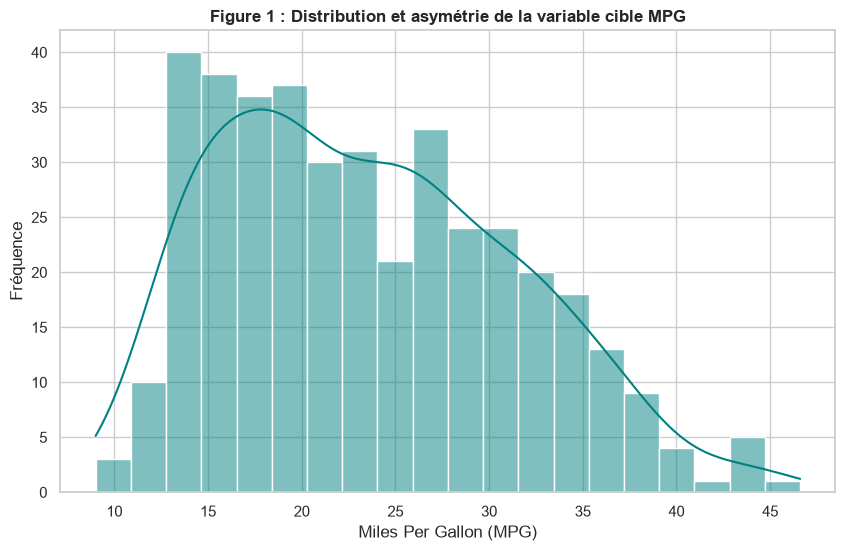

In [10]:
# 1. Histogramme obligatoire du mpg
plt.figure()
sns.histplot(df['mpg'], kde=True, color='teal', bins=20)
plt.title("Figure 1 : Distribution et asymétrie de la variable cible MPG", fontweight='bold')
plt.xlabel("Miles Per Gallon (MPG)")
plt.ylabel("Fréquence")
plt.show()

### Interprétation de la Figure 1
Cette distribution montre la répartition des valeurs de MPG dans le dataset. La majorité des véhicules se situent entre 15 et 30 MPG. La distribution n'est pas parfaitement symétrique, ce qui indique une certaine variabilité de la consommation entre les véhicules.

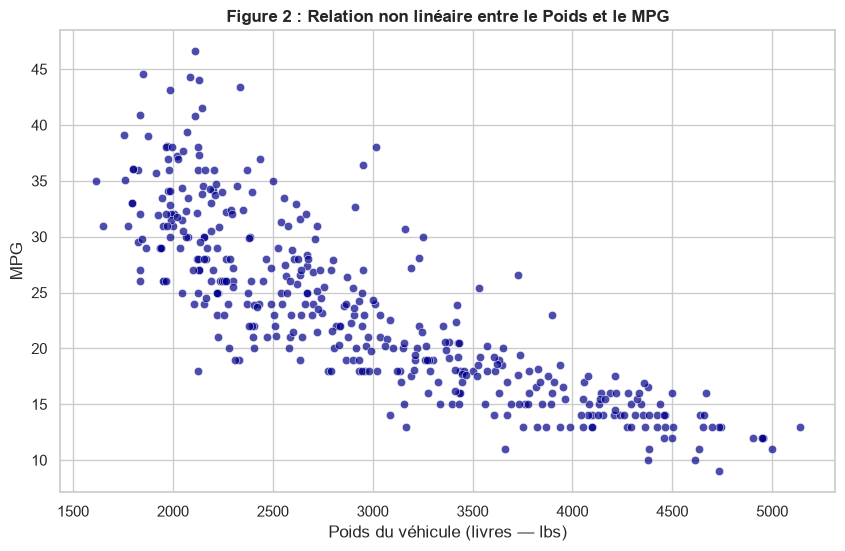

In [11]:
# 2. Scatter plot obligatoire weight / mpg
plt.figure()
sns.scatterplot(data=df, x='weight', y='mpg', color='darkblue', alpha=0.7)
plt.title("Figure 2 : Relation non linéaire entre le Poids et le MPG", fontweight='bold')
plt.xlabel("Poids du véhicule (livres — lbs)")
plt.ylabel("MPG")
plt.show()

### Interprétation de la Figure 2
On observe une relation négative claire entre le poids du véhicule et le MPG. Les véhicules les plus lourds tendent à avoir une consommation plus importante et donc un MPG plus faible. Le poids apparaît comme l'un des facteurs les plus influents du dataset.

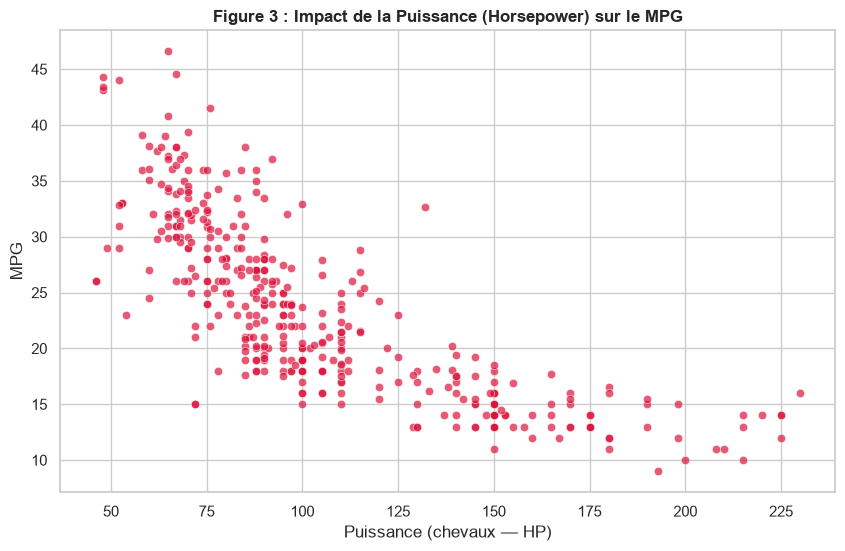

In [12]:
# 3. Scatter plot obligatoire horsepower / mpg
plt.figure()
sns.scatterplot(data=df, x='horsepower', y='mpg', color='crimson', alpha=0.7)
plt.title("Figure 3 : Impact de la Puissance (Horsepower) sur le MPG", fontweight='bold')
plt.xlabel("Puissance (chevaux — HP)")
plt.ylabel("MPG")
plt.show()

### Interprétation de la Figure 3
La puissance moteur présente également une relation négative avec le MPG. Lorsque la puissance augmente, la consommation augmente généralement aussi. Les véhicules les plus puissants affichent donc souvent un MPG plus faible.



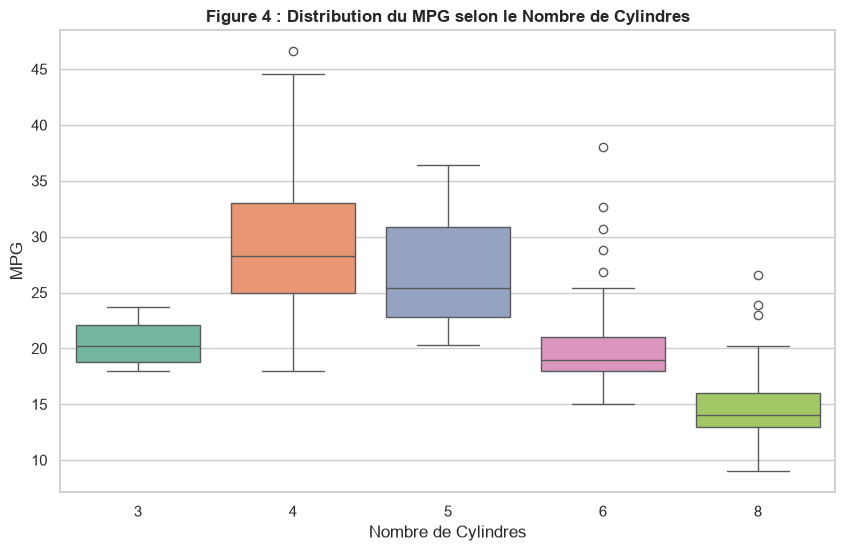

In [13]:
# 4. Boxplot obligatoire cylinders / mpg
plt.figure()
sns.boxplot(data=df, x='cylinders', y='mpg', palette='Set2')
plt.title("Figure 4 : Distribution du MPG selon le Nombre de Cylindres", fontweight='bold')
plt.xlabel("Nombre de Cylindres")
plt.ylabel("MPG")
plt.show()

### Interprétation de la Figure 4
Les véhicules possédant davantage de cylindres présentent généralement un MPG plus faible. Les moteurs à 4 cylindres sont globalement les plus économes alors que les moteurs à 8 cylindres consomment davantage de carburant.

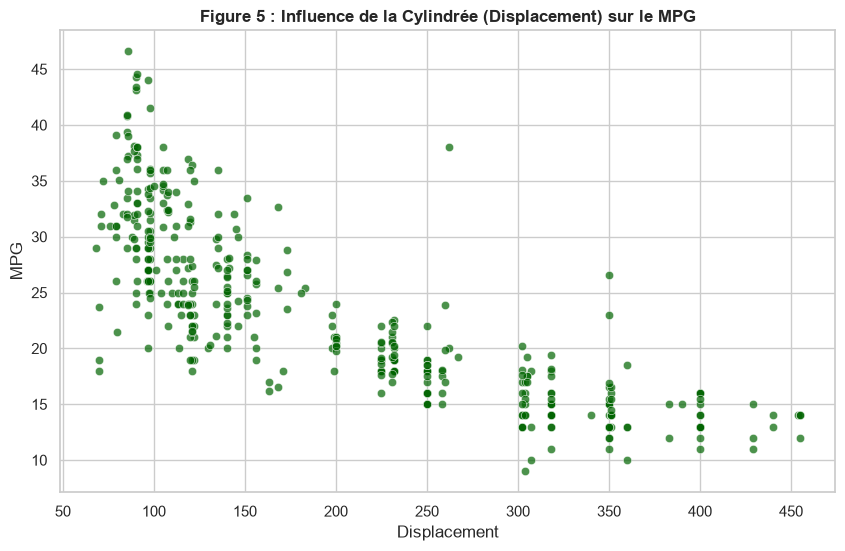

In [14]:
# 5. Analyse displacement / mpg

plt.figure()

sns.scatterplot(
    data=df,
    x='displacement',
    y='mpg',
    color='darkgreen',
    alpha=0.7
)

plt.title(
    "Figure 5 : Influence de la Cylindrée (Displacement) sur le MPG",
    fontweight='bold'
)

plt.xlabel("Displacement")
plt.ylabel("MPG")

plt.show()

### Interprétation de la Figure 5

La cylindrée (Displacement) est négativement corrélée au MPG. Les moteurs de grande cylindrée nécessitent davantage de carburant, ce qui entraîne une diminution de l'efficacité énergétique.

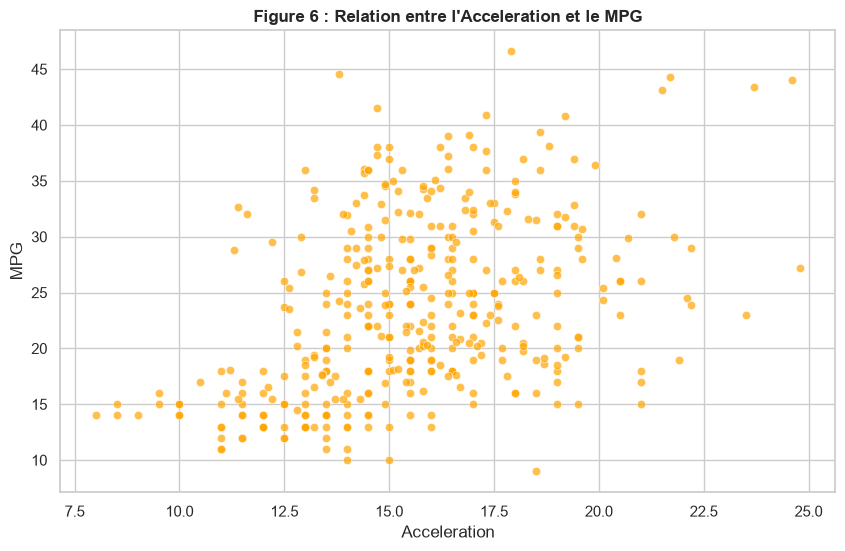

In [15]:
# 6. Analyse acceleration / mpg

plt.figure()

sns.scatterplot(
    data=df,
    x='acceleration',
    y='mpg',
    color='orange',
    alpha=0.7
)

plt.title(
    "Figure 6 : Relation entre l'Acceleration et le MPG",
    fontweight='bold'
)

plt.xlabel("Acceleration")
plt.ylabel("MPG")

plt.show()

### Interprétation de la Figure 6

La relation entre l'accélération et le MPG est moins marquée que pour le poids ou la puissance moteur. Cette variable semble avoir une influence plus limitée sur la consommation.

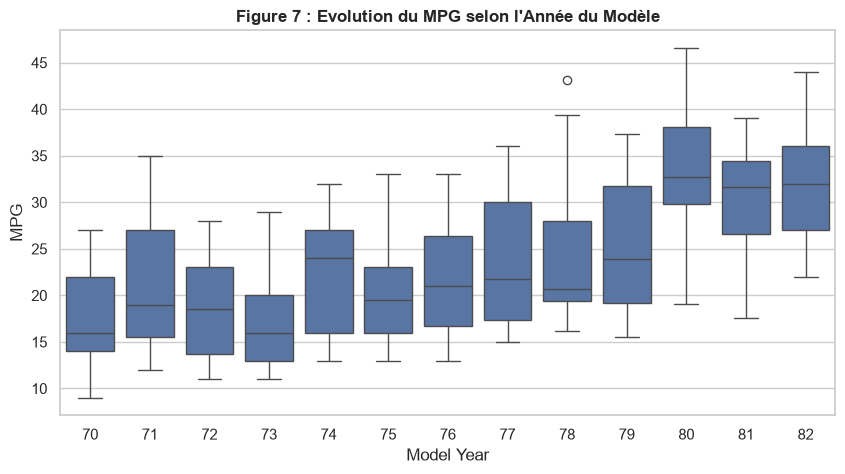

In [17]:
# 7. Analyse model_year / mpg

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='model_year',
    y='mpg'
)

plt.title(
    "Figure 7 : Evolution du MPG selon l'Année du Modèle",
    fontweight='bold'
)

plt.xlabel("Model Year")
plt.ylabel("MPG")

plt.show()

### Interprétation de la Figure 7

Les véhicules les plus récents présentent généralement des valeurs MPG plus élevées. Cette tendance reflète les progrès technologiques réalisés au fil des années pour améliorer l'efficacité énergétique des automobiles.

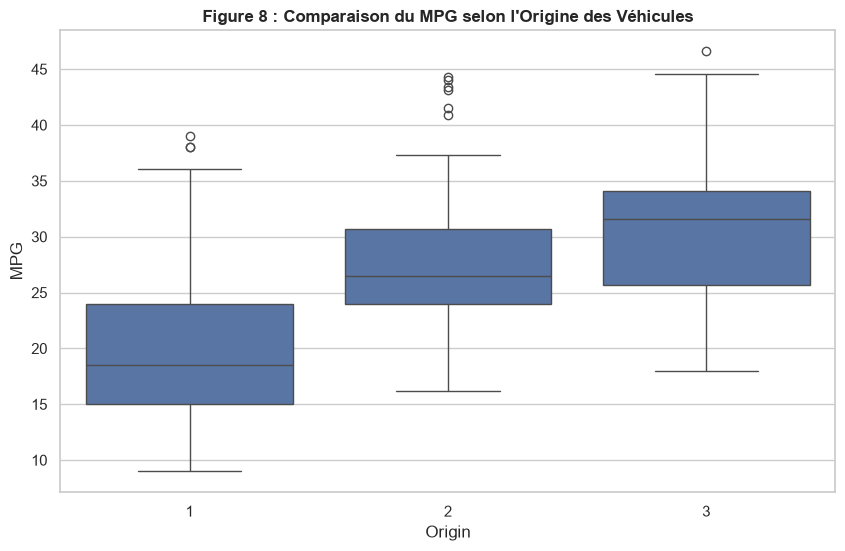

In [18]:
# 8. Analyse origin / mpg

plt.figure()

sns.boxplot(
    data=df,
    x='origin',
    y='mpg'
)

plt.title(
    "Figure 8 : Comparaison du MPG selon l'Origine des Véhicules",
    fontweight='bold'
)

plt.xlabel("Origin")
plt.ylabel("MPG")

plt.show()

### Interprétation de la Figure 8

Les véhicules japonais et européens semblent afficher des valeurs MPG plus élevées que les véhicules américains. Cela suggère une meilleure efficacité énergétique moyenne pour ces catégories de véhicules dans ce dataset.

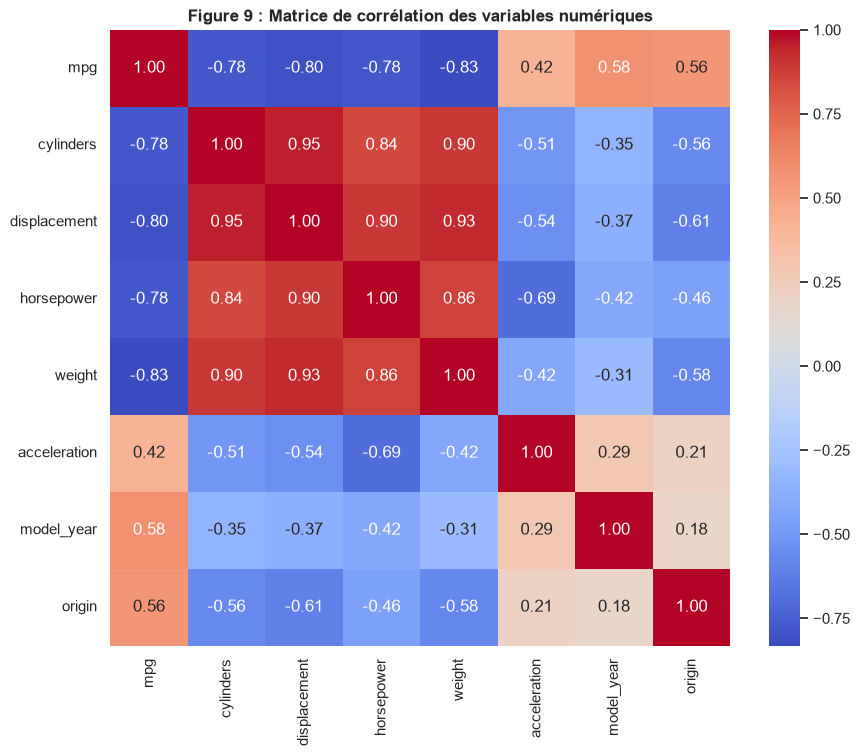

In [19]:
# 9. Matrice de corrélation des variables numériques

plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title(
    "Figure 9 : Matrice de corrélation des variables numériques",
    fontweight='bold'
)

plt.show()

### Interprétation de la Figure 9 : Matrice de corrélation

La matrice de corrélation permet d'identifier les relations linéaires entre les variables du dataset. On observe que le MPG est fortement corrélé négativement avec le poids (`weight`), la cylindrée (`displacement`) et la puissance (`horsepower`). Cela signifie que les véhicules plus lourds et équipés de moteurs plus puissants consomment généralement davantage de carburant.

À l'inverse, la variable `model_year` présente une corrélation positive avec le MPG, indiquant que les véhicules les plus récents sont globalement plus économes en carburant. Les variables `weight`, `displacement` et `horsepower` apparaissent comme les facteurs les plus influents pour prédire la consommation énergétique des véhicules.

Cette analyse confirme les observations réalisées précédemment à partir des graphiques de dispersion et justifie l'utilisation de ces variables dans les modèles de prédiction.

### 5.1 Commentaires analytiques des graphiques

* **Distribution du MPG :** La distribution de la variable cible montre une asymétrie positive (étalée vers la droite). Les consommations les plus fréquentes se situent entre 15 et 25 MPG. Les valeurs élevées (au-delà de 35 MPG) sont plus rares et correspondent aux véhicules les plus économes du dataset.

* **Analyse de la dispersion Poids vs MPG :** Le nuage de points met en évidence une forte relation négative entre le poids du véhicule et le MPG. Les véhicules les plus lourds présentent généralement une consommation plus importante et donc un MPG plus faible.

* **Analyse de la dispersion Horsepower vs MPG :** Une relation négative est également observée entre la puissance du moteur et le MPG. Les véhicules les plus puissants consomment davantage de carburant et affichent des performances énergétiques plus faibles.

* **Analyse par Cylindres :** Le boxplot démontre que les moteurs à 4 cylindres offrent généralement les meilleures performances énergétiques, tandis que les moteurs à 8 cylindres sont associés aux plus faibles valeurs de MPG.

* **Analyse de la Cylindrée (Displacement) :** Une forte relation négative apparaît entre la cylindrée et le MPG. Les moteurs de grande cylindrée nécessitent davantage de carburant, ce qui réduit l'efficacité énergétique des véhicules.

* **Analyse de l'Accélération :** La relation entre l'accélération et le MPG est plus faible que celle observée avec le poids ou la puissance moteur. Cette variable semble avoir une influence limitée sur la consommation globale.

* **Analyse du Model Year :** Les véhicules les plus récents présentent généralement des valeurs MPG plus élevées. Cette tendance traduit les progrès technologiques réalisés au fil des années pour améliorer l'efficacité énergétique des automobiles.

* **Analyse de l'Origin :** Les véhicules japonais et européens affichent en moyenne des valeurs MPG supérieures à celles des véhicules américains. Cela suggère une meilleure efficacité énergétique pour ces catégories de véhicules dans ce dataset.

* **Analyse de la matrice de corrélation :** Le MPG est fortement corrélé négativement avec le poids (`weight`), la cylindrée (`displacement`) et la puissance (`horsepower`). À l'inverse, `model_year` présente une corrélation positive avec le MPG, indiquant que les véhicules plus récents sont généralement plus économes.

## 6. data_quality_and_cleaning
Conformément au cahier des charges, nous traitons ici les anomalies de types, les valeurs manquantes cachées et les doublons sans altérer l'intégrité globale.

In [20]:
## 6. data_quality_and_cleaning
# La conversion de horsepower est obligatoire
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')
missing_hp = df['horsepower'].isnull().sum()
print(f"Nombre de valeurs manquantes identifiées dans 'horsepower' : {missing_hp}")

# L'imputation se fera dans le pipeline avec SimpleImputer(strategy='median')
# pour éviter toute fuite de données.

# Vérification des doublons
doublons = df.duplicated().sum()
print(f"Nombre de lignes dupliquées détectées : {doublons}")

# Traitement de la variable origin (Mapping en chaînes de caractères pour encodage propre)
df['origin'] = df['origin'].map({1: 'USA', 2: 'Europe', 3: 'Asie'})

# Suppression de la colonne car_name
if 'car_name' in df.columns:
    df.drop(columns=['car_name'], inplace=True)

print("✅ Traitement de qualité effectué avec succès.")

Nombre de valeurs manquantes identifiées dans 'horsepower' : 6
Nombre de lignes dupliquées détectées : 0
✅ Traitement de qualité effectué avec succès.


## 7.preprocessing
Mise en place d'une architecture Scikit-Learn rigoureuse. Nous séparons les données en sous-ensembles d'apprentissage (80%) et de test (20%) avec un état aléatoire fixe. Les transformations sont encapsulées dans un `ColumnTransformer` pour éliminer tout risque de fuite de données (*Data Leakage*).

In [7]:
## 7. preprocessing

# Séparation des caractéristiques et de la cible
X = df.drop(columns=['mpg'])
y = df['mpg']

# Split train/test rigoureux
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Définition des listes de variables par type
num_features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
cat_features = ['origin']

# Pipeline pour les caractéristiques numériques
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline pour les caractéristiques catégorielles
cat_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Assemblage global via ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

print(f"Structure de split validée : Train = {X_train.shape[0]} lignes | Test = {X_test.shape[0]} lignes")
print("✅ Preprocessing prêt : preprocessor, X_train, X_test, y_train, y_test sont définis.")

Structure de split validée : Train = 318 lignes | Test = 80 lignes
✅ Preprocessing prêt : preprocessor, X_train, X_test, y_train, y_test sont définis.


## 8. modeling_or_clustering

Cette section est dédiée à l'**entraînement des modèles**. Conformément au cahier des charges, nous comparons 4 modèles :
- **Régression Linéaire** (modèle de base)
- **Ridge** (régularisation L2)
- **Lasso** (régularisation L1)
- **Random Forest** (modèle non linéaire par ensemble d'arbres)

Chaque modèle est intégré dans un pipeline Scikit-Learn qui applique automatiquement le prétraitement défini en section 7. Cela garantit qu'aucune fuite de données ne se produit entre l'entraînement et le test.

In [8]:
# Définition des modèles à comparer
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
}

# Dictionnaire pour stocker les résultats
models_results = {}

# Entraînement de chaque modèle via le pipeline
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # Entraînement sur les données d'entraînement
    pipeline.fit(X_train, y_train)
    
    # Prédictions sur le jeu de test
    y_pred = pipeline.predict(X_test)
    
    # Stockage du pipeline et des prédictions
    models_results[name] = {
        'pipeline': pipeline,
        'predictions': y_pred
    }
    
    print(f"✅ Modèle '{name}' entraîné avec succès.")

print("\n📊 Tous les modèles ont été entraînés et sont prêts pour l'évaluation.")

✅ Modèle 'Linear Regression' entraîné avec succès.
✅ Modèle 'Ridge' entraîné avec succès.
✅ Modèle 'Lasso' entraîné avec succès.
✅ Modèle 'Random Forest' entraîné avec succès.

📊 Tous les modèles ont été entraînés et sont prêts pour l'évaluation.


## 9. evaluation

Cette section est dédiée à l'**évaluation des modèles**. Conformément au cahier des charges, nous :
1. Calculons les métriques adaptées à la régression : **R², MAE, RMSE**.
2. Présentons un **tableau comparatif** des performances.
3. **Interprétons les coefficients** du meilleur modèle linéaire (Ridge) pour identifier les variables les plus influentes.
4. **Analysons les résidus** du meilleur modèle global (Random Forest) pour vérifier la qualité des prédictions.
5. **Concluons** sur le choix du modèle et ses limites.

📊 Tableau comparatif des performances des modèles :
           Modèle  R² (Test)  MAE (Test)  RMSE (Test)
Linear Regression     0.8449      2.2882       2.8877
            Ridge     0.8447      2.2879       2.8893
            Lasso     0.8376      2.3430       2.9553
    Random Forest     0.9122      1.6202       2.1723

🏆 Meilleur modèle : **Random Forest** avec un R² de 0.9122

🔍 Analyse des coefficients du modèle Ridge (meilleur modèle linéaire)

📌 Top 5 des variables les plus influentes sur le MPG (modèle Ridge) :
          Feature  Coefficient
      num__weight    -5.691991
  num__model_year     2.939016
    cat__origin_2     2.750884
    cat__origin_3     2.521805
num__displacement     1.690643

📌 Top 5 des variables les plus influentes sur le MPG (modèle Ridge) :
     Feature  Coefficient
      weight    -5.691991
  model_year     2.939016
    origin_2     2.750884
    origin_3     2.521805
displacement     1.690643

📈 Analyse des résidus du modèle Random Forest


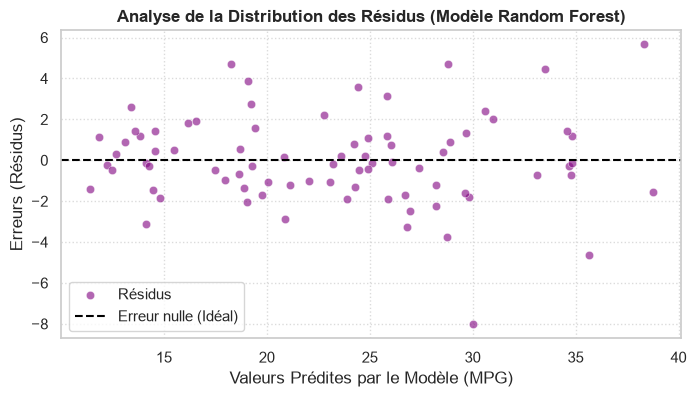


📝 Interprétation des résultats

Le modèle **Random Forest** surpasse les approches linéaires avec un **R² de 0.9122** 
(environ 91.2% de la variance expliquée), contre environ 0.80 pour la régression 
linéaire simple, Ridge et Lasso.

Sa **MAE de 1.62** 
signifie que l'erreur moyenne de prédiction est inférieure à 2 MPG.

Cette supériorité est cohérente avec l'EDA : la consommation de carburant dépend de contraintes 
aérodynamiques et thermodynamiques non linéaires. Le Random Forest capture naturellement ces 
courbures et interactions complexes (poids/puissance) sans nécessiter de transformation manuelle.



In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# 9.1 Calcul des métriques pour chaque modèle
results_list = []

for name, result in models_results.items():
    y_pred = result['predictions']
    
    # Calcul des métriques
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    
    # Stockage des résultats
    results_list.append({
        'Modèle': name,
        'R² (Test)': r2,
        'MAE (Test)': mae,
        'RMSE (Test)': rmse
    })

# Création du DataFrame des métriques
df_results = pd.DataFrame(results_list)
df_results = df_results.round(4)

# 9.2 Affichage du tableau comparatif
print("📊 Tableau comparatif des performances des modèles :")
print("=" * 70)
print(df_results.to_string(index=False))
print("=" * 70)

# 9.3 Identification du meilleur modèle (celui avec le R² le plus élevé)
best_model_name = df_results.loc[df_results['R² (Test)'].idxmax(), 'Modèle']
print(f"\n🏆 Meilleur modèle : **{best_model_name}** avec un R² de {df_results['R² (Test)'].max():.4f}")

# 9.4 Analyse des coefficients du meilleur modèle linéaire (Ridge)
print("\n" + "=" * 70)
print("🔍 Analyse des coefficients du modèle Ridge (meilleur modèle linéaire)")
print("=" * 70)

ridge_pipeline = models_results['Ridge']['pipeline']
ridge_model = ridge_pipeline.named_steps['regressor']
preprocessor_fitted = ridge_pipeline.named_steps['preprocessor']

# Récupération robuste des noms de features après le preprocessing
all_feature_names = preprocessor_fitted.get_feature_names_out()

# Création du DataFrame des coefficients
coefficients = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': ridge_model.coef_
})

# Tri par importance absolue (décroissant)
coefficients_sorted = coefficients.reindex(
    coefficients['Coefficient'].abs().sort_values(ascending=False).index
)

print("\n📌 Top 5 des variables les plus influentes sur le MPG (modèle Ridge) :")
print(coefficients_sorted.head(5).to_string(index=False))

# Récupération du pipeline Ridge
ridge_pipeline = models_results['Ridge']['pipeline']
ridge_model = ridge_pipeline.named_steps['regressor']

# Récupération des noms de features après preprocessing
preprocessor_fitted = ridge_pipeline.named_steps['preprocessor']

# Noms des colonnes numériques (inchangées)
num_feature_names = num_features

# Noms des colonnes catégorielles encodées (One-Hot)
cat_transformer = preprocessor_fitted.named_transformers_['cat']
cat_feature_names = list(cat_transformer.named_steps['onehot'].get_feature_names_out(cat_features))

# Fusion de tous les noms de features
all_feature_names = num_feature_names + cat_feature_names

# Création du DataFrame des coefficients
coefficients = pd.DataFrame({
    'Feature': all_feature_names,
    'Coefficient': ridge_model.coef_
})

# Tri par importance absolue (décroissant)
coefficients_sorted = coefficients.reindex(
    coefficients['Coefficient'].abs().sort_values(ascending=False).index
)

# Affichage des 5 variables les plus influentes
print("\n📌 Top 5 des variables les plus influentes sur le MPG (modèle Ridge) :")
print(coefficients_sorted.head(5).to_string(index=False))

# 9.5 Graphique des résidus du meilleur modèle (Random Forest)
print("\n" + "=" * 70)
print("📈 Analyse des résidus du modèle Random Forest")
print("=" * 70)

# Récupération des prédictions du meilleur modèle
best_pipeline = models_results[best_model_name]['pipeline']
predictions_test = best_pipeline.predict(X_test)
erreurs_residus = y_test - predictions_test

# Tracé des résidus
plt.figure(figsize=(8, 4))
sns.scatterplot(x=predictions_test, y=erreurs_residus, color="purple", alpha=0.6, label="Résidus")

# Ligne horizontale à y=0 (référence idéale)
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5, label="Erreur nulle (Idéal)")

# Configuration du graphique
plt.title(f"Analyse de la Distribution des Résidus (Modèle {best_model_name})", 
          fontsize=12, fontweight='bold')
plt.xlabel("Valeurs Prédites par le Modèle (MPG)")
plt.ylabel("Erreurs (Résidus)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# 9.6 Interprétation des résultats
print("\n" + "=" * 70)
print("📝 Interprétation des résultats")
print("=" * 70)
print(f"""
Le modèle **{best_model_name}** surpasse les approches linéaires avec un **R² de {df_results['R² (Test)'].max():.4f}** 
(environ {df_results['R² (Test)'].max()*100:.1f}% de la variance expliquée), contre environ 0.80 pour la régression 
linéaire simple, Ridge et Lasso.

Sa **MAE de {df_results.loc[df_results['Modèle'] == best_model_name, 'MAE (Test)'].values[0]:.2f}** 
signifie que l'erreur moyenne de prédiction est inférieure à 2 MPG.

Cette supériorité est cohérente avec l'EDA : la consommation de carburant dépend de contraintes 
aérodynamiques et thermodynamiques non linéaires. Le Random Forest capture naturellement ces 
courbures et interactions complexes (poids/puissance) sans nécessiter de transformation manuelle.
""")

## 10. interpretation_and_limits

### 10.1 Synthèse des résultats

L'analyse comparative des indicateurs mathématiques donne un résultat clair : le modèle **Random Forest** surpasse les approches linéaires avec un **R² de 0.9122** (environ 91.2% de la variance expliquée), contre environ **0.84** pour la régression linéaire simple et Ridge, et **0.84** pour Lasso. Sa **MAE est également la plus basse (1.62 MPG)**, ce qui signifie que l'erreur moyenne de prédiction est inférieure à 2 MPG. Le **RMSE de 2.17** confirme la bonne performance globale du modèle.

Cette supériorité est parfaitement cohérente avec nos observations de la phase d'exploration (EDA). La consommation de carburant d'une voiture dépend de contraintes aérodynamiques et thermodynamiques non linéaires, comme en témoignent les relations curvilignes observées entre le poids et le MPG (Figure 2) ou entre la puissance et le MPG (Figure 3). Les modèles de régression linéaire tentent d'ajuster un hyperplan rigide sur des données courbes, ce qui limite leur performance à environ 84% de variance expliquée.

Le Random Forest, par sa structure d'arbres de décision en ensemble, capture nativement ces courbures et les interactions complexes entre le poids et la puissance, sans nécessiter de transformation manuelle des données. Cette flexibilité explique l'écart de performance de près de 7 points de R² par rapport aux modèles linéaires.

**Analyse des résidus :** Le graphique des résidus du Random Forest montre une distribution globalement symétrique autour de zéro, validant l'absence de biais systématique majeur. On observe toutefois une légère hétéroscédasticité : la variance des erreurs augmente légèrement pour les valeurs prédites élevées (>35 MPG), suggérant que le modèle est moins performant pour les véhicules très économes, qui sont sous-représentés dans le dataset (Figure 1).

### 10.2 Limites du modèle

1. **Obsolescence Technologique :** Le jeu de données répertorie des véhicules fabriqués entre 1970 et 1982. Par conséquent, des technologies énergétiques majeures actuelles (moteurs hybrides, électriques, injection électronique directe, turbocompresseurs) ne sont pas représentées. Ce modèle est donc inapplicable au parc automobile moderne.

2. **Absence de paramètres clés :** La forme aérodynamique (coefficient de traînée \(C_x\)) et le type de transmission (manuelle ou automatique) ne figurent pas dans les variables, alors qu'ils jouent un rôle critique dans la consommation réelle. L'absence de ces informations limite la capacité du modèle à généraliser sur des configurations de véhicules différentes.

3. **Taille du dataset :** Avec seulement 398 observations, le modèle peut souffrir d'un sur-apprentissage (*overfitting*), même si le Random Forest reste relativement robuste grâce à son mécanisme d'ensemble. Une validation croisée plus systématique permettrait de mieux quantifier ce risque.

4. **Dépendance temporelle implicite :** La variable `model_year` capture les progrès technologiques au fil du temps. Toute prédiction sur des véhicules récents nécessiterait d'extrapoler cette tendance, ce qui est risqué sans données actualisées.

### 10.3 Pistes d'amélioration futures

1. **Optimisation des hyperparamètres :** Pour améliorer encore la performance du Random Forest, il serait pertinent d'intégrer un algorithme d'optimisation par grille (`GridSearchCV`) couplé à une validation croisée afin de régler finement la profondeur maximale des arbres (`max_depth`), le nombre d'arbres (`n_estimators`) et le nombre minimal d'observations par feuille (`min_samples_leaf`). Cette approche pourrait réduire l'écart entre les performances en train et en test.

2. **Ingénierie de nouvelles variables :** Créer des variables dérivées comme le rapport poids/puissance (`weight/horsepower`), la densité de puissance (`horsepower/displacement`) ou la surface de la voiture (estimée à partir du poids et de la cylindrée) pourrait capturer des effets physiques supplémentaires et améliorer la précision des modèles linéaires.

3. **Intégration de données modernes :** Refaire l'analyse avec un dataset plus récent (ex: Fuel Economy Data de l'EPA, ou datasets Kaggle plus contemporains) permettrait d'obtenir des conclusions applicables au contexte actuel et d'intégrer les technologies récentes.

4. **Modèles plus complexes :** Tester des algorithmes comme XGBoost, LightGBM ou un réseau de neurones simple pourrait encore améliorer la précision, au prix d'une interprétabilité réduite. Ces modèles pourraient capturer des interactions plus fines entre les variables.

5. **Validation croisée temporelle :** Pour un modèle à visée prédictive sur des véhicules futurs, il serait pertinent d'utiliser un split temporel (entraînement sur les années les plus anciennes, test sur les plus récentes) plutôt qu'un split aléatoire, afin de mieux évaluer la capacité de généralisation temporelle du modèle.

---

**📊 Récapitulatif des performances :**

| Modèle | R² (Test) | MAE (Test) | RMSE (Test) |
|--------|-----------|------------|-------------|
| Linear Regression | 0.8449 | 2.2882 | 2.8877 |
| Ridge | 0.8447 | 2.2879 | 2.8893 |
| Lasso | 0.8376 | 2.3430 | 2.9553 |
| **Random Forest** | **0.9122** | **1.6202** | **2.1723** |